In [2]:
import numpy as np
import matplotlib.pyplot as plt
from dls.foundations import (
    square,
    sigmoid,
    plot_chain,
    plot_chain_deriv,
    leaky_relu,
    matrix_function_forward_sum,
    matrix_function_backward_1,
    matrix_function_backward_sum_1,
)


In [3]:
print("Python list operations:")
a = [1, 2, 3]
b = [4, 5, 6]
print("a+b:", a + b)
try:
    print(a * b)
except TypeError:
    print("a*b has no meaning for Python lists")
print()
print("numpy array operations:")
a = np.array([1, 2, 3])
b = np.array([4, 5, 6])
print("a+b:", a + b)
print("a*b:", a * b)

# axis=0 is rows
# axis=1 is columns
a = np.array([[1, 2], [3, 4]])
print("a:")
print(a)
print("a.sum(axis=0):", a.sum(axis=0))
print("a.sum(axis=1):", a.sum(axis=1))


Python list operations:
a+b: [1, 2, 3, 4, 5, 6]
a*b has no meaning for Python lists

numpy array operations:
a+b: [5 7 9]
a*b: [ 4 10 18]
a:
[[1 2]
 [3 4]]
a.sum(axis=0): [4 6]
a.sum(axis=1): [3 7]


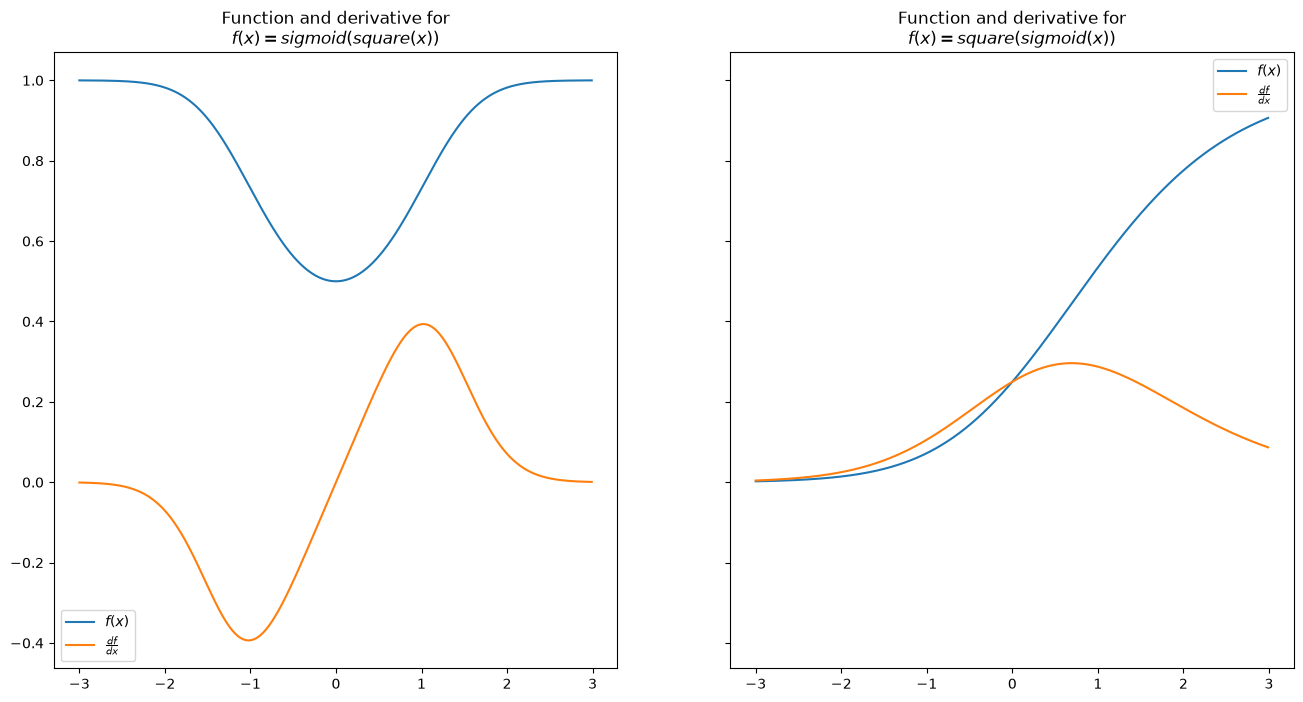

In [4]:
fig, ax = plt.subplots(1, 2, sharey=True, figsize=(16, 8))  # 2 Rows, 1 Col

chain_1 = [square, sigmoid]
chain_2 = [sigmoid, square]

PLOT_RANGE = np.arange(-3, 3, 0.01)
plot_chain(ax[0], chain_1, PLOT_RANGE)
plot_chain_deriv(ax[0], chain_1, PLOT_RANGE)

ax[0].legend(["$f(x)$", "$\\frac{df}{dx}$"])
ax[0].set_title("Function and derivative for\n$f(x) = sigmoid(square(x))$")

plot_chain(ax[1], chain_2, PLOT_RANGE)
plot_chain_deriv(ax[1], chain_2, PLOT_RANGE)
ax[1].legend(["$f(x)$", "$\\frac{df}{dx}$"])
ax[1].set_title("Function and derivative for\n$f(x) = square(sigmoid(x))$")

plt.show()


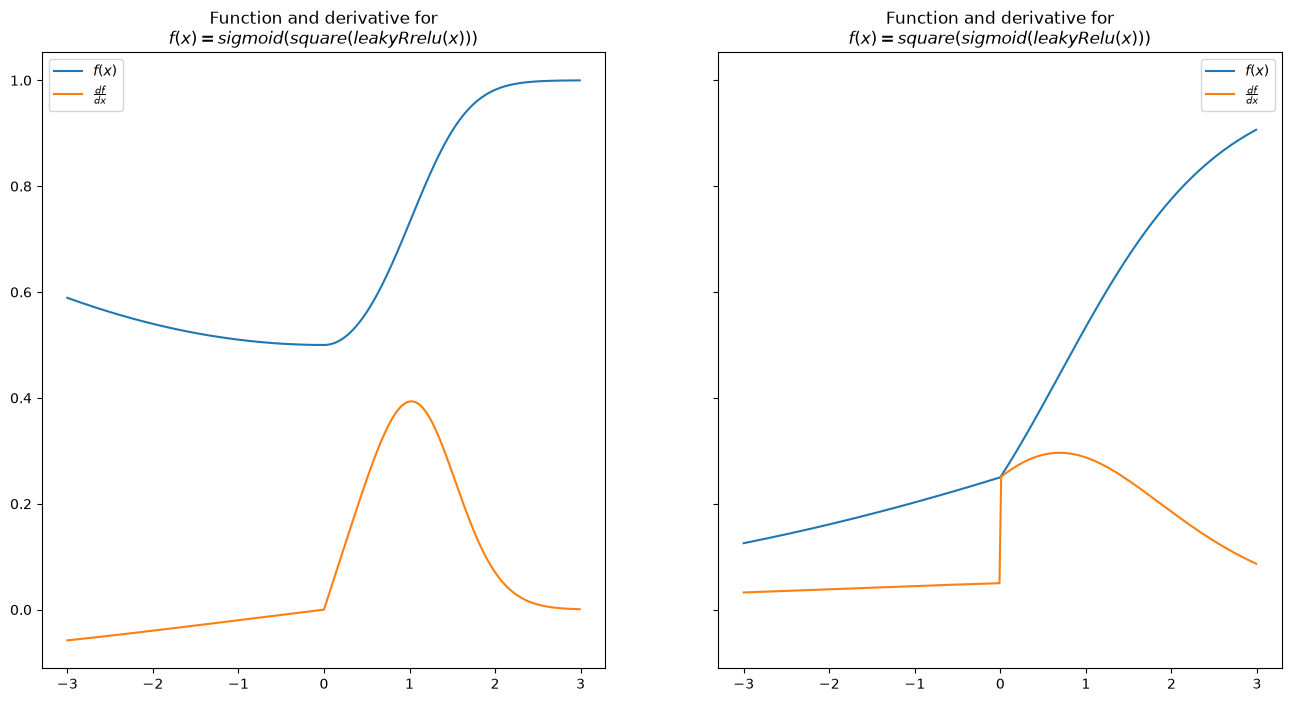

In [5]:
fig, ax = plt.subplots(1, 2, sharey=True, figsize=(16, 8))  # 2 Rows, 1 Col

chain_1 = [leaky_relu, square, sigmoid]
chain_2 = [leaky_relu, sigmoid, square]

PLOT_RANGE = np.arange(-3, 3, 0.01)
plot_chain(ax[0], chain_1, PLOT_RANGE, length=3)
plot_chain_deriv(ax[0], chain_1, PLOT_RANGE, length=3)

ax[0].legend(["$f(x)$", "$\\frac{df}{dx}$"])
ax[0].set_title("Function and derivative for\n$f(x) = sigmoid(square(leakyRrelu(x)))$")

plot_chain(ax[1], chain_2, PLOT_RANGE, length=3)
plot_chain_deriv(ax[1], chain_2, PLOT_RANGE, length=3)
ax[1].legend(["$f(x)$", "$\\frac{df}{dx}$"])
ax[1].set_title("Function and derivative for\n$f(x) = square(sigmoid(leakyRelu(x)))$")

plt.show()

In [6]:
X = np.array([[0.4723, 0.6151, -1.7262]])
W = np.transpose(np.array([[0.01, 0.01, -0.01]]), (1, 0))
print(X)
print(W)
print(matrix_function_backward_1(X, W, sigmoid))

[[ 0.4723  0.6151 -1.7262]]
[[ 0.01]
 [ 0.01]
 [-0.01]]
[[ 0.00249951  0.00249951 -0.00249951]]


In [7]:
np.random.seed(190204)
X = np.random.randn(3, 3)
W = np.random.randn(3, 2)

print("X:")
print(X)

print("L:")
print(round(matrix_function_forward_sum(X, W, sigmoid), 4))
print()
print("dLdX:")
print(matrix_function_backward_sum_1(X, W, sigmoid))

X1 = X.copy()
X1[0, 0] += 0.001

print(
    round(
        (
            matrix_function_forward_sum(X1, W, sigmoid)
            - matrix_function_forward_sum(X, W, sigmoid)
        )
        / 0.001,
        4,
    )
)


X:
[[-1.57752816 -0.6664228   0.63910406]
 [-0.56152218  0.73729959 -1.42307821]
 [-1.44348429 -0.39128029  0.1539322 ]]
L:
2.3755

dLdX:
[[ 0.2488887  -0.37478057  0.01121962]
 [ 0.12604152 -0.27807404 -0.13945837]
 [ 0.22992798 -0.36623443 -0.02252592]]
0.2489


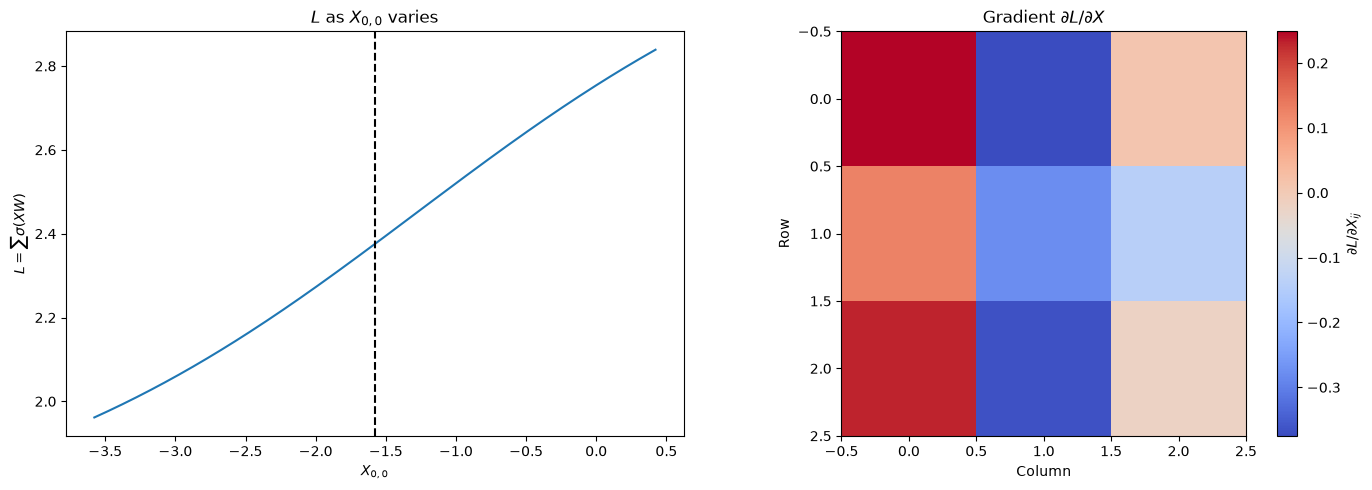

In [8]:
row, col = 0, 0
values = np.linspace(X[row, col] - 2, X[row, col] + 2, 200)

losses = []
gradients = []

for value in values:
    X_plot = X.copy()
    X_plot[row, col] = value

    losses.append(matrix_function_forward_sum(X_plot, W, sigmoid))
    gradients.append(matrix_function_backward_sum_1(X_plot, W, sigmoid)[row, col])

dLdX = matrix_function_backward_sum_1(X, W, sigmoid)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].plot(values, losses)
ax[0].axvline(X[row, col], color="black", linestyle="--")
ax[0].set_title(r"$L$ as $X_{0,0}$ varies")
ax[0].set_xlabel(r"$X_{0,0}$")
ax[0].set_ylabel(r"$L = \sum \sigma(XW)$")

ax[1].imshow(dLdX, cmap="coolwarm")
ax[1].set_title(r"Gradient $\partial L / \partial X$")
ax[1].set_xlabel("Column")
ax[1].set_ylabel("Row")
fig.colorbar(ax[1].images[0], ax=ax[1], label=r"$\partial L / \partial X_{ij}$")

plt.tight_layout()
plt.show()
